In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv(r"/content/Temperatures.csv")
print(df.head())

   YEAR    JAN    FEB    MAR    APR    MAY    JUN    JUL    AUG    SEP    OCT  \
0  1901  22.40  24.14  29.07  31.91  33.41  33.18  31.21  30.39  30.47  29.97   
1  1902  24.93  26.58  29.77  31.78  33.73  32.91  30.92  30.73  29.80  29.12   
2  1903  23.44  25.03  27.83  31.39  32.91  33.00  31.34  29.98  29.85  29.04   
3  1904  22.50  24.73  28.21  32.02  32.64  32.07  30.36  30.09  30.04  29.20   
4  1905  22.00  22.83  26.68  30.01  33.32  33.25  31.44  30.68  30.12  30.67   

     NOV    DEC  ANNUAL  JAN-FEB  MAR-MAY  JUN-SEP  OCT-DEC  
0  27.31  24.49   28.96    23.27    31.46    31.27    27.25  
1  26.31  24.04   29.22    25.75    31.76    31.09    26.49  
2  26.08  23.65   28.47    24.24    30.71    30.92    26.26  
3  26.36  23.63   28.49    23.62    30.95    30.66    26.40  
4  27.52  23.82   28.30    22.25    30.00    31.33    26.57  


In [17]:
df.dropna(inplace = True)
df.drop_duplicates(inplace = True)

In [18]:
print(df.duplicated().sum())

0


In [19]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
df = df[~((df<(Q1 - 1.5 * IQR)) | (df>(Q3 + 1.5 * IQR)))]

In [20]:
X = df.drop(columns= ['YEAR', 'ANNUAL'])
y = df['ANNUAL'].apply(lambda x : 1 if x > df['ANNUAL'].mean() else 0)

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    f1_score,
    recall_score,
    roc_auc_score,
    auc,
    RocCurveDisplay,
    classification_report
    )

In [34]:
splits =[0.20,0.30,0.35]
accuracy = []
models=[]
results=[]

for i in splits:
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = i, random_state = 42)

  model = RandomForestClassifier()

  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)

  acc = accuracy_score(y_pred, y_test)
  accuracy.append(acc)

  models.append(model)
  results.append((y_test,y_pred))

  print(f"Accuracy score of test size {i} is {acc}")

Accuracy score of test size 0.2 is 0.9583333333333334
Accuracy score of test size 0.3 is 0.9166666666666666
Accuracy score of test size 0.35 is 0.926829268292683


Confusion matrix of test size 0 is 
[[13  1]
 [ 0 10]]


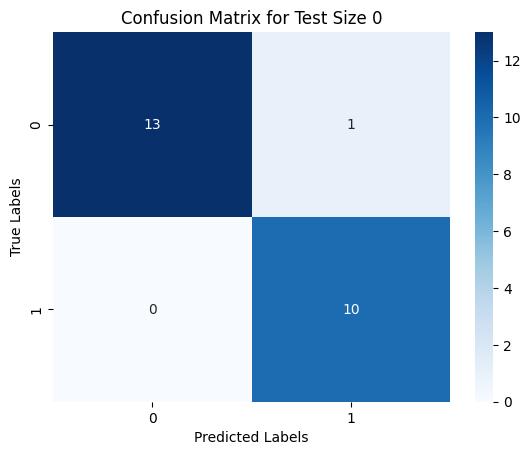

Confusion matrix of test size 1 is 
[[19  1]
 [ 2 14]]


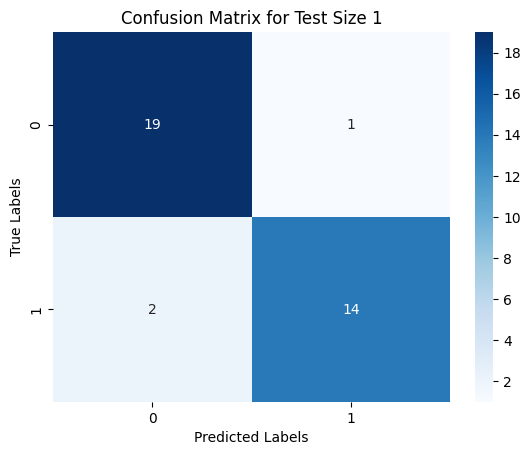

Confusion matrix of test size 2 is 
[[23  1]
 [ 2 15]]


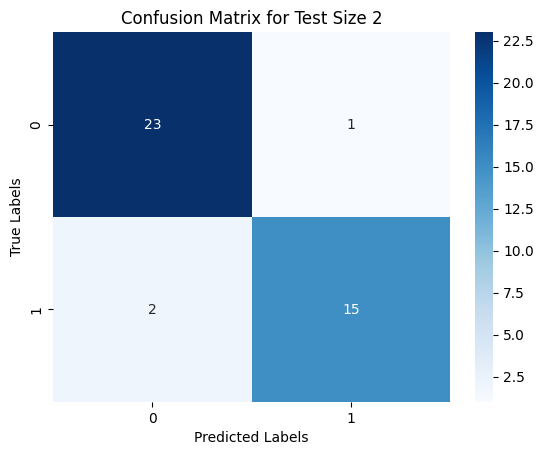

In [35]:
#confusion matrix
for i in range(len(splits)):
  y_test,y_pred = results[i]

  cf = confusion_matrix(y_test,y_pred)

  plt.figure()
  sns.heatmap(cf, annot=True, fmt='d', cmap='Blues')
  plt.title(f'Confusion Matrix for Test Size {i}')
  plt.xlabel('Predicted Labels')
  plt.ylabel('True Labels')

  print(f"Confusion matrix of test size {i} is \n{cf}")
  plt.show()

In [29]:
for i in splits:
  print(f"classification report of test size {i}\n", classification_report(y_test,y_pred))
  print(f"precision score of test size {i}", precision_score(y_test,y_pred))
  print(f"recall score of test size {i}", recall_score(y_test,y_pred))
  print(f"f1 score of test size {i}", f1_score(y_test,y_pred))
  print()

classification report of test size 0.2
               precision    recall  f1-score   support

           0       0.92      0.96      0.94        24
           1       0.94      0.88      0.91        17

    accuracy                           0.93        41
   macro avg       0.93      0.92      0.92        41
weighted avg       0.93      0.93      0.93        41

precision score of test size 0.2 0.9375
recall score of test size 0.2 0.8823529411764706
f1 score of test size 0.2 0.9090909090909091

classification report of test size 0.3
               precision    recall  f1-score   support

           0       0.92      0.96      0.94        24
           1       0.94      0.88      0.91        17

    accuracy                           0.93        41
   macro avg       0.93      0.92      0.92        41
weighted avg       0.93      0.93      0.93        41

precision score of test size 0.3 0.9375
recall score of test size 0.3 0.8823529411764706
f1 score of test size 0.3 0.90909090909090

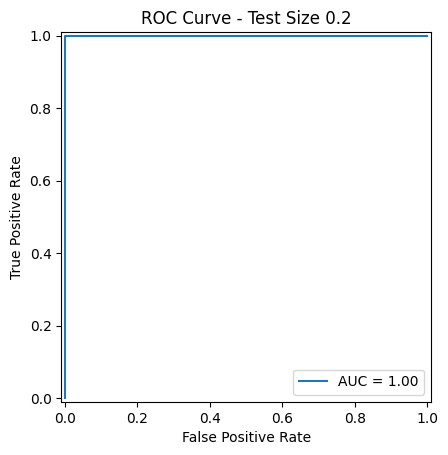

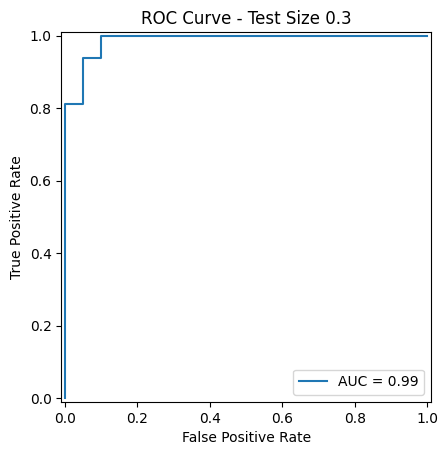

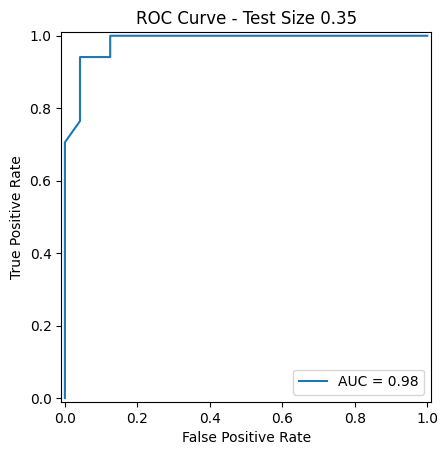

In [38]:
from sklearn.metrics import roc_curve

for i in range(len(splits)):
  y_test, y_pred = results[i]

  _, X_test, _, _ = train_test_split(X, y, test_size=splits[i], random_state=42)

  y_proba = models[i].predict_proba(X_test)[:, 1]

  fpr, tpr, thresholds = roc_curve(y_test, y_proba)
  roc_auc = auc(fpr, tpr)

  display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
  display.plot()
  plt.title(f"ROC Curve - Test Size {splits[i]}")
  plt.show()

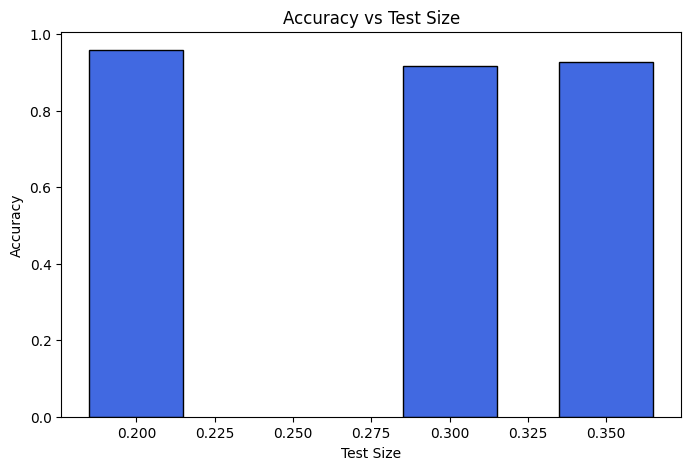

In [42]:
plt.figure(figsize=(8, 5))
plt.bar(splits, accuracy, width=0.03, color='royalblue', edgecolor='black')

# Set explicit x-ticks to match your test sizes exactly
#plt.xticks(splits)

plt.xlabel("Test Size")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Test Size")
plt.show()

In [44]:
best_index = accuracy.index(max(accuracy))

best_model = models[best_index]

print("Best Test Size:", splits[best_index])
print("Best Accuracy:", accuracy[best_index])

Best Test Size: 0.2
Best Accuracy: 0.9583333333333334


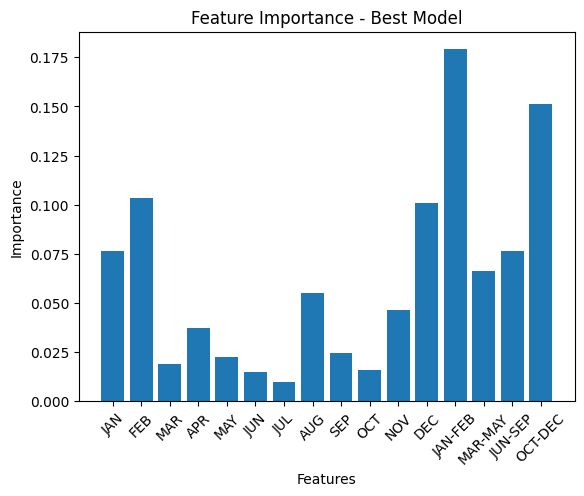

In [45]:
importance = best_model.feature_importances_

plt.bar(X.columns, importance)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - Best Model")

plt.xticks(rotation=45)
plt.show()